# Chapter 7: Evolutionary Computing and Hybrid ANFIS Systems

This notebook collects the runnable examples of *Chapter 7: Evolutionary Computing and Hybrid ANFIS Systems* from the textbook *Computational and Biological Intelligence* (A. Movasagh). Run the cells in order; each example is independent unless noted. Figures are also saved as PNG files in this folder.

## Learning objectives

After working through this notebook you should be able to:

- explain the idea of evolutionary computing and when it is used.
- describe the steps of the genetic algorithm and implement it from scratch.
- use the genetic algorithm for feature selection in medical data.
- explain the principles of particle swarm optimization.
- describe the motivation for hybrid systems.
- explain and implement the five-layer structure of ANFIS and its hybrid learning.
- implement differential evolution and explain how its parameters affect the search.
- tune the hyperparameters of a medical model with an evolutionary algorithm and evaluate the result honestly.


In [1]:
%matplotlib inline

## Example 7.1: A genetic algorithm from scratch for optimizing a highly oscillating function

Script version: `example_7_1.py`

Best x found = 1.8477, f(x) = 2.8426
True maximum (grid search): x = 1.8505, f = 2.8503
Best fitness in generations 1, 10, 30, 60: [2.6502, 2.8398, 2.8426, 2.8426]


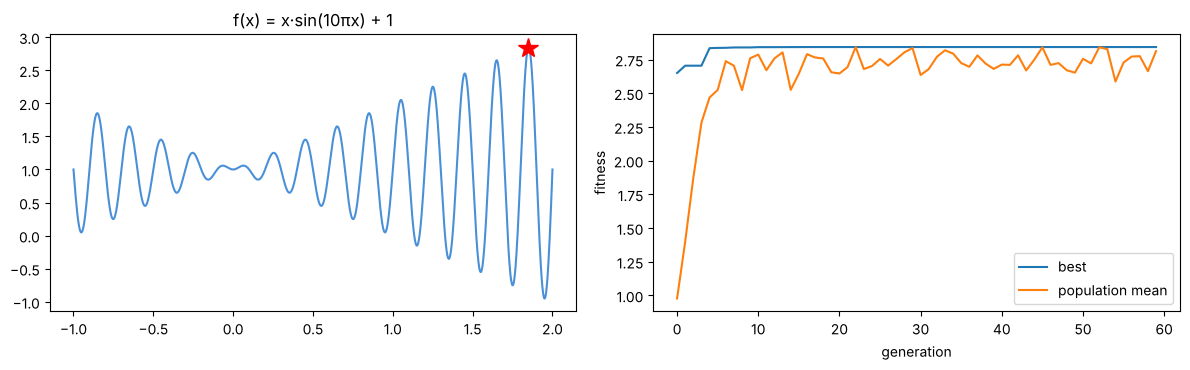

In [2]:
# Example 7.1: A genetic algorithm from scratch — finding the maximum of a highly oscillating function
import numpy as np
import matplotlib.pyplot as plt
 
f = lambda x: x * np.sin(10 * np.pi * x) + 1.0          # many local maxima on [-1, 2]
rng = np.random.default_rng(42)
BITS, POP, GENS, PC, PM = 22, 50, 60, 0.8, 0.01
 
def decode(chrom):                                       # binary string -> real number in [-1, 2]
    value = chrom @ (2 ** np.arange(BITS)[::-1])
    return -1 + 3 * value / (2 ** BITS - 1)
 
pop = rng.integers(0, 2, (POP, BITS))                    # 1) random initial population
best_hist, mean_hist = [], []
for g in range(GENS):
    x = np.array([decode(c) for c in pop]); fit = f(x)   # 2) fitness evaluation
    best_hist.append(fit.max()); mean_hist.append(fit.mean())
    # 3) selection: tournament of size 3
    idx = [max(rng.choice(POP, 3, replace=False), key=lambda i: fit[i]) for _ in range(POP)]
    parents = pop[idx]
    # 4) crossover: single point
    children = parents.copy()
    for i in range(0, POP, 2):
        if rng.random() < PC:
            cut = rng.integers(1, BITS)
            children[i, cut:], children[i + 1, cut:] = parents[i + 1, cut:], parents[i, cut:]
    # 5) mutation: flip bits with small probability
    flip = rng.random(children.shape) < PM
    children[flip] = 1 - children[flip]
    children[0] = pop[fit.argmax()]                      # elitism: keep the best one
    pop = children
 
x = np.array([decode(c) for c in pop]); best = x[f(x).argmax()]
print(f"Best x found = {best:.4f}, f(x) = {f(best):.4f}")
grid = np.linspace(-1, 2, 200001); print(f"True maximum (grid search): x = {grid[f(grid).argmax()]:.4f}, f = {f(grid).max():.4f}")
print("Best fitness in generations 1, 10, 30, 60:", [round(float(best_hist[i]), 4) for i in (0, 9, 29, 59)])
 
fig, ax = plt.subplots(1, 2, figsize=(12, 3.8))
xs = np.linspace(-1, 2, 2000); ax[0].plot(xs, f(xs), c="#4a90d9"); ax[0].plot(best, f(best), "r*", ms=15)
ax[0].set_title("f(x) = x·sin(10πx) + 1")
ax[1].plot(best_hist, label="best"); ax[1].plot(mean_hist, label="population mean")
ax[1].set_xlabel("generation"); ax[1].set_ylabel("fitness"); ax[1].legend()
plt.tight_layout(); plt.savefig("fig7_1.png", dpi=300)

## Example 7.2: Feature selection with a genetic algorithm for breast cancer diagnosis

Script version: `example_7_2.py`

In [3]:
# Example 7.2: Feature selection with a genetic algorithm for breast cancer diagnosis
import numpy as np
from sklearn.datasets import load_breast_cancer
from sklearn.model_selection import cross_val_score
from sklearn.neighbors import KNeighborsClassifier
from sklearn.pipeline import make_pipeline
from sklearn.preprocessing import StandardScaler
 
data = load_breast_cancer(); X, y = data.data, data.target
rng = np.random.default_rng(0)
model = make_pipeline(StandardScaler(), KNeighborsClassifier(5))
cache = {}
 
def fitness(mask):
    key = mask.tobytes()
    if key not in cache:
        if mask.sum() == 0: cache[key] = 0.0
        else:
            acc = cross_val_score(model, X[:, mask.astype(bool)], y, cv=5).mean()
            cache[key] = acc - 0.002 * mask.sum()       # reward accuracy, penalize many features
    return cache[key]
 
POP, GENS, n = 20, 15, X.shape[1]
pop = (rng.random((POP, n)) < 0.5).astype(int)
for g in range(GENS):
    fit = np.array([fitness(m) for m in pop])
    order = fit.argsort()[::-1]; elite = pop[order[:4]]
    kids = []
    while len(kids) < POP - 4:
        a, b = pop[rng.choice(order[:10], 2, replace=False)]
        cut = rng.integers(1, n); child = np.r_[a[:cut], b[cut:]]
        child[rng.random(n) < 0.05] ^= 1
        kids.append(child)
    pop = np.vstack([elite, kids])
    if g % 5 == 4: print(f"generation {g + 1:>2}: best fitness = {fit.max():.4f}")
 
best = pop[np.argmax([fitness(m) for m in pop])].astype(bool)
all_acc = cross_val_score(model, X, y, cv=5).mean()
sel_acc = cross_val_score(model, X[:, best], y, cv=5).mean()
print(f"All 30 features      -> CV accuracy = {all_acc:.3f}")
print(f"GA-selected {best.sum():>2} feat. -> CV accuracy = {sel_acc:.3f}")
print("Selected:", ", ".join(np.array(data.feature_names)[best][:8]), "...")

generation  5: best fitness = 0.9589


generation 10: best fitness = 0.9589


generation 15: best fitness = 0.9589


All 30 features      -> CV accuracy = 0.965
GA-selected 10 feat. -> CV accuracy = 0.979
Selected: mean perimeter, mean concave points, concavity error, fractal dimension error, worst radius, worst texture, worst perimeter, worst area ...


## Example 7.3: Particle swarm optimization on the Rastrigin function

Script version: `example_7_3.py`

In [4]:
# Example 7.3: Particle swarm optimization (PSO) — inspired by the collective movement of bird flocks
import numpy as np
 
def rastrigin(p):  # a classic test function with many local minima, global minimum 0 at (0,0)
    return 10 * p.shape[-1] + (p ** 2 - 10 * np.cos(2 * np.pi * p)).sum(-1)
 
rng = np.random.default_rng(1)
N, D, iters, w, c1, c2 = 30, 2, 100, 0.7, 1.5, 1.5
pos = rng.uniform(-5, 5, (N, D)); vel = np.zeros((N, D))
pbest, pbest_val = pos.copy(), rastrigin(pos)
gbest = pbest[pbest_val.argmin()].copy()
for t in range(iters):
    r1, r2 = rng.random((N, D)), rng.random((N, D))
    vel = w * vel + c1 * r1 * (pbest - pos) + c2 * r2 * (gbest - pos)   # personal + social pull
    pos = np.clip(pos + vel, -5, 5)
    val = rastrigin(pos)
    better = val < pbest_val
    pbest[better], pbest_val[better] = pos[better], val[better]
    gbest = pbest[pbest_val.argmin()].copy()
    if t in (0, 9, 49, 99): print(f"iteration {t + 1:>3}: best value = {pbest_val.min():.5f} at {gbest.round(4)}")

iteration   1: best value = 7.77721 at [-0.9197  0.1785]
iteration  10: best value = 1.09833 at [-0.0181  1.0089]
iteration  50: best value = 0.00103 at [0.0018 0.0014]
iteration 100: best value = 0.00000 at [ 0. -0.]


## Example 7.4: Implementing ANFIS with hybrid learning from scratch

Script version: `example_7_4.py`

RMSE after epoch 1: 0.1504 | after epoch 600: 0.0495
Learned MF centers: [-2.83 -0.81  0.78  2.86]
Learned MF widths : [0.78 0.83 0.83 0.76]
Rule consequents (p, r): [(-0.33, -0.82), (-0.06, -1.74), (-0.11, 1.7), (-0.49, 1.26)]


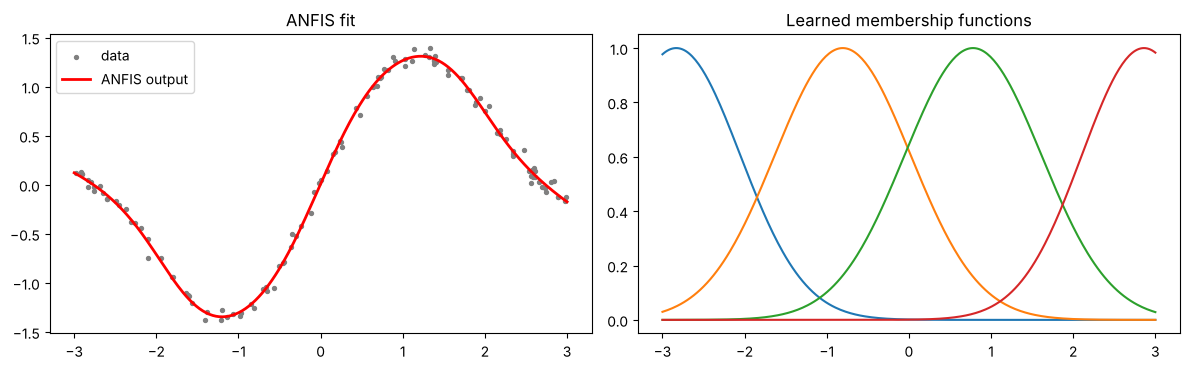

In [5]:
# Example 7.4: ANFIS from scratch — a Sugeno fuzzy system that learns its parameters from data
# Hybrid learning: consequents by least squares, premise (membership) params by gradient descent
import numpy as np
import matplotlib.pyplot as plt
 
rng = np.random.default_rng(0)
x = np.sort(rng.uniform(-3, 3, 120)); y = np.sin(1.5 * x) + 0.3 * x + rng.normal(0, 0.05, x.size)
 
M = 4                                                     # number of fuzzy rules / membership functions
c = np.linspace(-3, 3, M); s = np.full(M, 0.45)        # Layer 1: initial (too narrow) Gaussian MFs
 
def layers(x, c, s):
    mu = np.exp(-((x[:, None] - c) ** 2) / (2 * s ** 2))  # Layer 1: fuzzification
    w = mu                                                # Layer 2: rule firing strength
    wn = w / w.sum(1, keepdims=True)                      # Layer 3: normalization
    A = np.hstack([wn * x[:, None], wn])                  # Layer 4 design matrix: wn*(p*x + r)
    return mu, wn, A
 
lr, hist = 0.3, []
for epoch in range(600):
    mu, wn, A = layers(x, c, s)
    theta, *_ = np.linalg.lstsq(A, y, rcond=None)          # forward pass: least squares for p, r
    p, r = theta[:M], theta[M:]
    f = p * x[:, None] + r                                # rule outputs
    out = (wn * f).sum(1)                                 # Layer 5: weighted sum
    err = out - y; hist.append(np.sqrt(np.mean(err ** 2)))
    # backward pass: gradient of MSE w.r.t. c and s
    d_wn = err[:, None] * (f - out[:, None]) / mu.sum(1, keepdims=True)
    d_c = (d_wn * mu * (x[:, None] - c) / s ** 2).mean(0)
    d_s = (d_wn * mu * (x[:, None] - c) ** 2 / s ** 3).mean(0)
    c -= lr * d_c; s = np.maximum(s - lr * d_s, 0.2)
 
print(f"RMSE after epoch 1: {hist[0]:.4f} | after epoch 600: {hist[-1]:.4f}")
print("Learned MF centers:", c.round(2)); print("Learned MF widths :", s.round(2))
print("Rule consequents (p, r):", [(round(float(a), 2), round(float(b), 2)) for a, b in zip(p, r)])
 
xs = np.linspace(-3, 3, 300); mu_s, wn_s, A_s = layers(xs, c, s)
fig, ax = plt.subplots(1, 2, figsize=(12, 3.8))
ax[0].scatter(x, y, s=8, c="gray", label="data"); ax[0].plot(xs, A_s @ theta, "r", lw=2, label="ANFIS output")
ax[0].legend(); ax[0].set_title("ANFIS fit")
ax[1].plot(xs, mu_s); ax[1].set_title("Learned membership functions")
plt.tight_layout(); plt.savefig("fig7_2.png", dpi=300)

## Example 7.5: Differential evolution from scratch, compared with PSO on the 10-dimensional Rastrigin function

Script version: `example_7_5.py`

DE, CR=0.1 : best value over 5 runs  mean =   0.000   min =   0.000   max =   0.000
DE, CR=0.9 : best value over 5 runs  mean =  19.437   min =  14.961   max =  24.302
PSO        : best value over 5 runs  mean =   9.353   min =   4.975   max =  18.904
evaluations per run: 20040


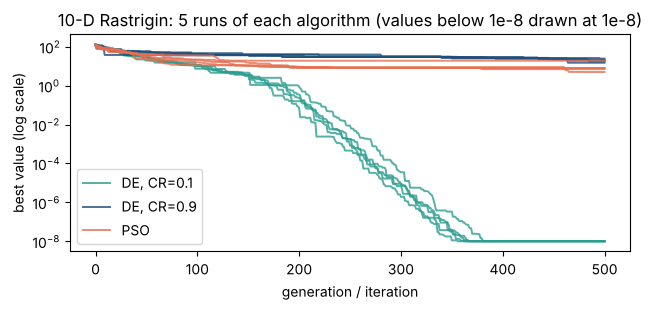

In [6]:
# Example 7.5: Differential evolution (DE/rand/1/bin) from scratch, compared with PSO on the 10-D Rastrigin function
import numpy as np
import matplotlib.pyplot as plt

def rastrigin(p):  # global minimum 0 at the origin
    return 10 * p.shape[-1] + (p ** 2 - 10 * np.cos(2 * np.pi * p)).sum(-1)

def de(f, D, N=40, F=0.5, CR=0.9, gens=500, lo=-5.12, hi=5.12, seed=0):
    rng = np.random.default_rng(seed)
    pop = rng.uniform(lo, hi, (N, D)); fit = f(pop); history = [fit.min()]
    for g in range(gens):
        for i in range(N):
            a, b, c = pop[rng.choice([j for j in range(N) if j != i], 3, replace=False)]
            mutant = np.clip(a + F * (b - c), lo, hi)            # mutation: a difference vector
            cross = rng.random(D) < CR
            cross[rng.integers(D)] = True                        # at least one gene from the mutant
            trial = np.where(cross, mutant, pop[i])               # binomial crossover
            ft = f(trial)
            if ft <= fit[i]:                                      # greedy one-to-one selection
                pop[i], fit[i] = trial, ft
        history.append(fit.min())
    return pop[fit.argmin()], fit.min(), history

def pso(f, D, N=40, w=0.7, c1=1.5, c2=1.5, iters=500, lo=-5.12, hi=5.12, seed=0):
    rng = np.random.default_rng(seed)
    x = rng.uniform(lo, hi, (N, D)); v = np.zeros((N, D))
    pb, pbv = x.copy(), f(x); gb = pb[pbv.argmin()].copy(); history = [pbv.min()]
    for t in range(iters):
        r1, r2 = rng.random((N, D)), rng.random((N, D))
        v = w * v + c1 * r1 * (pb - x) + c2 * r2 * (gb - x)
        x = np.clip(x + v, lo, hi); val = f(x)
        better = val < pbv; pb[better], pbv[better] = x[better], val[better]
        gb = pb[pbv.argmin()].copy(); history.append(pbv.min())
    return gb, pbv.min(), history

D = 10
algs = {"DE, CR=0.1": lambda s: de(rastrigin, D, CR=0.1, seed=s),
        "DE, CR=0.9": lambda s: de(rastrigin, D, CR=0.9, seed=s),
        "PSO":        lambda s: pso(rastrigin, D, seed=s)}
results = {name: [alg(s) for s in range(5)] for name, alg in algs.items()}
for name, runs in results.items():
    best = np.array([r[1] for r in runs])
    print(f"{name:<11}: best value over 5 runs  mean = {best.mean():7.3f}   min = {best.min():7.3f}   max = {best.max():7.3f}")
print("evaluations per run:", 40 * 501)

plt.figure(figsize=(6.5, 3.2))
for name, col in [("DE, CR=0.1", "#2A9D8F"), ("DE, CR=0.9", "#1F4E79"), ("PSO", "#E76F51")]:
    for k, r in enumerate(results[name]):
        plt.semilogy(np.maximum(r[2], 1e-8), color=col, alpha=0.8, lw=1.4, label=name if k == 0 else None)
plt.xlabel("generation / iteration"); plt.ylabel("best value (log scale)")
plt.title("10-D Rastrigin: 5 runs of each algorithm (values below 1e-8 drawn at 1e-8)"); plt.legend()
plt.tight_layout(); plt.savefig("fig7_5.png", dpi=300)

## Example 7.6: Tuning the hyperparameters of an SVM with grid search, random search, and differential evolution

Script version: `example_7_6.py`

default SVC (C=1, gamma='scale'): CV acc = 0.9736
grid search   (121 evals): C = 31.623, gamma = 0.00100, CV acc = 0.9802


random search (40 evals): best CV acc per seed = [0.9802 0.9802 0.9802 0.9758 0.978 ]
DE            (40 evals): best CV acc per seed = [0.978  0.9802 0.9802 0.978  0.978 ]
one misclassified sample changes the mean CV accuracy by 1/455 = 0.0022
test set (114 patients): accuracy = 0.9825, sensitivity = 0.976, specificity = 0.986, missed cancers = 1


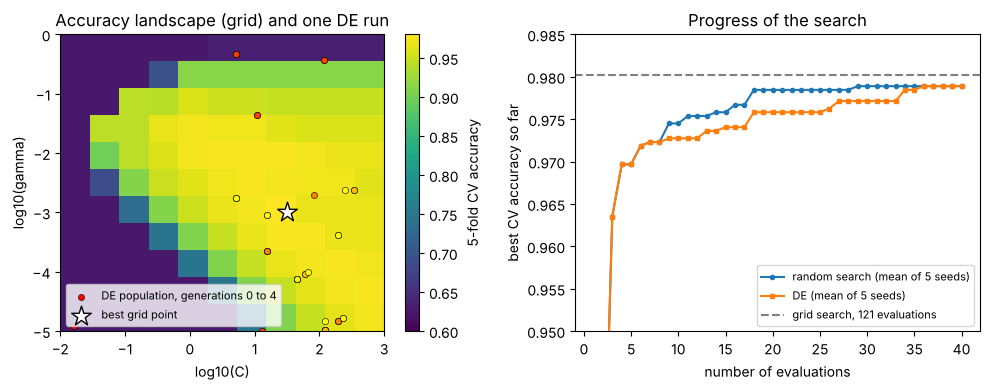

In [7]:
# Example 7.6: Tuning an SVM for breast cancer diagnosis — grid search, random search, and differential evolution
import numpy as np
import matplotlib.pyplot as plt
from sklearn.datasets import load_breast_cancer
from sklearn.model_selection import train_test_split, StratifiedKFold, cross_val_score
from sklearn.pipeline import make_pipeline
from sklearn.preprocessing import StandardScaler
from sklearn.svm import SVC
from sklearn.metrics import confusion_matrix

X, y = load_breast_cancer(return_X_y=True)                  # 0 = malignant, 1 = benign
X_tr, X_te, y_tr, y_te = train_test_split(X, y, test_size=0.2, stratify=y, random_state=42)
cv = StratifiedKFold(5, shuffle=True, random_state=0)
lo, hi = np.array([-2.0, -5.0]), np.array([3.0, 0.0])        # search space: log10(C), log10(gamma)

def make_model(p):
    return make_pipeline(StandardScaler(), SVC(C=10 ** p[0], gamma=10 ** p[1]))

def cv_score(p):                                             # the fitness: mean 5-fold CV accuracy
    return cross_val_score(make_model(p), X_tr, y_tr, cv=cv).mean()

def random_search(n, seed):
    pts = np.random.default_rng(seed).uniform(lo, hi, (n, 2))
    sc = np.array([cv_score(p) for p in pts])
    return pts[sc.argmax()], np.maximum.accumulate(sc)

def de_search(N, gens, seed, F=0.6, CR=0.7):
    rng = np.random.default_rng(seed)
    pop = rng.uniform(lo, hi, (N, 2)); fit = np.array([cv_score(p) for p in pop])
    trace, snapshots = list(np.maximum.accumulate(fit)), [pop.copy()]
    for g in range(gens):
        for i in range(N):
            a, b, c = pop[rng.choice([j for j in range(N) if j != i], 3, replace=False)]
            trial = np.where(rng.random(2) < CR, np.clip(a + F * (b - c), lo, hi), pop[i])
            ft = cv_score(trial)
            if ft >= fit[i]: pop[i], fit[i] = trial, ft          # greedy selection (we maximize)
            trace.append(fit.max())
        snapshots.append(pop.copy())
    return pop[fit.argmax()], np.array(trace), snapshots

# 1) grid search: 11 x 11 = 121 evaluations
gC, gG = np.linspace(lo[0], hi[0], 11), np.linspace(lo[1], hi[1], 11)
grid = np.array([[cv_score([c, g]) for c in gC] for g in gG])
i, j = np.unravel_index(grid.argmax(), grid.shape); best_grid = np.array([gC[j], gG[i]])
print(f"default SVC (C=1, gamma='scale'): CV acc = {cross_val_score(make_pipeline(StandardScaler(), SVC()), X_tr, y_tr, cv=cv).mean():.4f}")
print(f"grid search   (121 evals): C = {10 ** best_grid[0]:.3f}, gamma = {10 ** best_grid[1]:.5f}, CV acc = {grid.max():.4f}")

# 2) random search and 3) DE, each with a budget of 40 evaluations, repeated with 5 seeds
rs = [random_search(40, s) for s in range(5)]
de = [de_search(8, 4, s) for s in range(5)]
print("random search (40 evals): best CV acc per seed =", np.round([r[1][-1] for r in rs], 4))
print("DE            (40 evals): best CV acc per seed =", np.round([d[1][-1] for d in de], 4))
print(f"one misclassified sample changes the mean CV accuracy by 1/{len(y_tr)} = {1 / len(y_tr):.4f}")

# the test set is used once, for the configuration chosen on the training data
model = make_model(best_grid).fit(X_tr, y_tr)
tn, fp, fn, tp = confusion_matrix(y_te, model.predict(X_te), labels=[1, 0]).ravel()   # positive class = malignant
print(f"test set ({len(y_te)} patients): accuracy = {(tp + tn) / len(y_te):.4f}, "
      f"sensitivity = {tp / (tp + fn):.3f}, specificity = {tn / (tn + fp):.3f}, missed cancers = {fn}")

fig, ax = plt.subplots(1, 2, figsize=(10, 4))
im = ax[0].imshow(grid, origin="lower", extent=[lo[0], hi[0], lo[1], hi[1]], aspect="auto", cmap="viridis", vmin=0.6)
plt.colorbar(im, ax=ax[0], label="5-fold CV accuracy")
for k, P in enumerate(de[0][2]):
    ax[0].scatter(P[:, 0], P[:, 1], s=20, color=plt.cm.autumn(k / 4), edgecolor="k", lw=0.4,
                  label="DE population, generations 0 to 4" if k == 0 else None)
ax[0].scatter(*best_grid, marker="*", s=220, c="white", edgecolor="k", label="best grid point")
ax[0].set_xlabel("log10(C)"); ax[0].set_ylabel("log10(gamma)"); ax[0].legend(loc="lower left", fontsize=8)
ax[0].set_title("Accuracy landscape (grid) and one DE run")
n = np.arange(1, 41)
ax[1].plot(n, np.mean([r[1] for r in rs], 0), "o-", ms=3, label="random search (mean of 5 seeds)")
ax[1].plot(n, np.mean([d[1] for d in de], 0), "s-", ms=3, label="DE (mean of 5 seeds)")
ax[1].axhline(grid.max(), ls="--", color="gray", label="grid search, 121 evaluations")
ax[1].set_xlabel("number of evaluations"); ax[1].set_ylabel("best CV accuracy so far"); ax[1].set_ylim(0.95, 0.985)
ax[1].legend(fontsize=8); ax[1].set_title("Progress of the search")
plt.tight_layout(); plt.savefig("fig7_6.png", dpi=300)